#### Task 4: Bar chart of churned vs non-churned customers for each InternetService type.

Loaded Telco-Customer-Churn_sample.csv: 2,000 rows  (SIMULATED STAND-IN DATA, not the real file)

Customers by InternetService and Churn:
Churn             No  Yes
InternetService          
DSL              485  197
Fiber optic      545  325
No               376   72

Churn rate by InternetService (%):
InternetService
DSL            28.9
Fiber optic    37.4
No             16.1


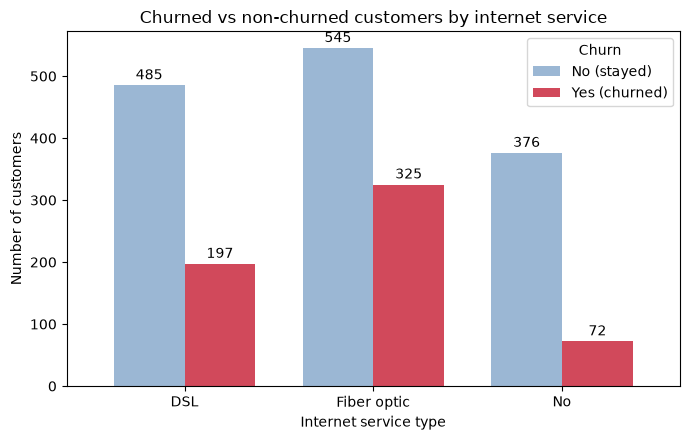


Chart saved to churn_by_internet_service.png


In [2]:
import os
import numpy as np
import pandas as pd
 
HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
CANON = ["CustomerID", "Gender", "SeniorCitizen", "Partner", "Dependents", "Tenure", "PhoneService",
         "InternetService", "Contract", "MonthlyCharges", "TotalCharges", "Churn"]
 
 
def load_data():
    """Load the real Telco-Customer-Churn.csv if it is in this folder, otherwise the simulated sample."""
    for name in ("Telco-Customer-Churn.csv", "WA_Fn-UseC_-Telco-Customer-Churn.csv", "Telco-Customer-Churn_sample.csv"):
        path = os.path.join(HERE, name)
        if os.path.exists(path):
            df = pd.read_csv(path)
            print(f"Loaded {name}: {len(df):,} rows" + ("  (SIMULATED STAND-IN DATA, not the real file)" if "sample" in name else ""))
            break
    else:
        raise FileNotFoundError("Put Telco-Customer-Churn.csv (or run generate_sample_data.py) in the same folder.")
    df = df.rename(columns={c: next((k for k in CANON if k.lower() == c.lower()), c) for c in df.columns})   # customerID -> CustomerID, tenure -> Tenure
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")        # blank strings become NaN
    return df
 
import matplotlib
if "__file__" in globals():            # plain script: save to file; notebook: show inline
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
 
df = load_data()
 
# Excel equivalent: PivotTable (Rows = InternetService, Columns = Churn, Values = Count) + Insert > Clustered Column chart
counts = pd.crosstab(df["InternetService"], df["Churn"]).loc[["DSL", "Fiber optic", "No"], ["No", "Yes"]]
print("\nCustomers by InternetService and Churn:")
print(counts.to_string())
print("\nChurn rate by InternetService (%):")
print((counts["Yes"] / counts.sum(axis=1) * 100).round(1).to_string())
 
ax = counts.plot(kind="bar", figsize=(7, 4.5), color=["#9bb7d4", "#d1495b"], rot=0, width=0.75)
ax.set_xlabel("Internet service type")
ax.set_ylabel("Number of customers")
ax.set_title("Churned vs non-churned customers by internet service")
ax.legend(title="Churn", labels=["No (stayed)", "Yes (churned)"])
for container in ax.containers:
    ax.bar_label(container, padding=2)
plt.tight_layout()
plt.savefig(os.path.join(HERE, "churn_by_internet_service.png"), dpi=150)
if "__file__" not in globals():
    plt.show()
print("\nChart saved to churn_by_internet_service.png")